# Preliminaries

## Imports etc.

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

In [2]:
import numpy as np
from matplotlib import pyplot as plt

In [3]:
import puffins as pf
from puffins import plotting as pplt

In [4]:
plt.rcParams.update(pplt.plt_rc_params_custom)

## Setup bins

In [5]:
# Setup bins for histograms, uniform width in log space.
bin_edges_log = np.arange(-3, 8.01, 0.1)
bin_centers_log = np.arange(-2.95, 7.96, 0.1)
bin_edges_rain = np.exp(bin_edges_log)
bin_centers_rain = np.exp(bin_centers_log)
print(np.min(bin_edges_rain), np.max(bin_edges_rain))

0.049787068367863944 2980.95798704176


# Define stochastic model

In [6]:
DT_MV19 = 1 / 60.  # 1 minute
HOURS_IN_YEAR = 365 * 24


class StochRain:
    def __init__(self, q_thresh_start=65.0, q_thresh_end=64.8, q_init=64.9, q_min=1., noise_amp_wet=17.0,
                 noise_amp_dry=3.0, dt=DT_MV19, evap_clim=0.1, moist_flux_conv_clim=0.2, 
                 rain_rate=9.):
        """Default values taken from Martinez-Villalobos and Neelin 2019, Fig. 2.
        
        Units should follow those in their paper: 
        - mm for CWV
        - mm / hour for E, C, and rain rate
        - mm / (hour^1/2) for the noise amplitudes
        - hours for the timestep
        
        """
        # Convert all units to S.I.
        self.q_thresh_start = q_thresh_start * 1e-3
        self.q_thresh_end = q_thresh_end * 1e-3
        self.q_init = q_init * 1e-3
        self.q_min = q_min * 1e-3

        self.noise_amp_wet = noise_amp_wet * 1e-3 * 3600. ** -0.5
        self.noise_amp_dry = noise_amp_dry * 1e-3 * 3600. ** -0.5

        self.dt = dt * 3600.

        self.evap_clim = evap_clim * 1e-3 / 3600.
        self.moist_flux_conv_clim = moist_flux_conv_clim * 1e-3 / 3600.
        self.rain_rate = rain_rate * 1e-3 / 3600.
       

    def _stoch_moist_conv(self, *args, **kwargs):
        """The stochastic process for moisture flux convergence fluctuations."""
        return np.random.normal(*args, **kwargs)


    def _setup(self, num_iter):
        self.num_rain_events = 0
        self.num_dry_events = 0

        self.rain_event_lengths = []
        self.rain_event_accums = []
        self.dry_event_lengths = []

        self.this_rain_event_accum = 0.0
        self.this_rain_event_length = 0
        self.this_dry_event_length = 0

        num_iter = int(num_iter)
        self.q = np.zeros(num_iter) * np.nan

        self.rain = np.zeros(num_iter) * np.nan
        self.is_raining = np.zeros(num_iter) * np.nan

        # Can generate the noise component for the whole integration now, since
        # it's uncorrelated white noise.  Then at each timestep, multiply this 
        # by either the dry or wet noise parameter depending on if it's raining.
        self._moist_conv_stoch_term = self._stoch_moist_conv(size=num_iter)

        self.q[0] = self.q_init
        if self.q_init > self.q_thresh_start:
            self.rain[0] = self.rain_rate * self.dt
            self.is_raining[0] = True
        else:
            self.rain[0] = 0.
            self.is_raining[0] = False


    def _rain_started(self, n):
        self.dry_event_lengths.append(self.this_dry_event_length)
        self.num_rain_events += 1
        self.this_rain_event_accum = self.rain[n]
        self.this_rain_event_length = 1

    def _rain_continuing(self, n):
        self.this_rain_event_length += 1
        self.this_rain_event_accum += self.rain[n]

    def _raining(self, n):
        self.rain[n] = self.rain_rate * self.dt
        if self.rain[n - 1] == 0:
            self._rain_started(n)
        else:
            self._rain_continuing(n)

    def _dry_started(self, n):
        self.rain_event_lengths.append(self.this_rain_event_length)
        self.rain_event_accums.append(self.this_rain_event_accum)
        self.this_dry_event_length = 1
        self.num_dry_events += 1

    def _dry_continuing(self, n):
        self.this_dry_event_length += 1

    def _not_raining(self, n):
        self.rain[n] = 0.0
        if self.rain[n - 1] > 0:
            self._dry_started(n)
        else:
            self._dry_continuing(n)
        self.rain[n] = 0.0

    def _iter_cwv(self, n):
        if self.is_raining[n]:
            noise_amp = self.noise_amp_wet
            rain_rate = self.rain_rate
        else:
            noise_amp = self.noise_amp_dry
            rain_rate = 0.

        self.q[n] = self.q[n - 1] + (
            self._moist_conv_stoch_term[n] * noise_amp - 
            rain_rate + 
            self.evap_clim +
            self.moist_flux_conv_clim
        ) * self.dt

        # Don't allow it to go below a minimum value.
        if self.q[n] < self.q_min:
            self.q[n] = self.q_min

    def step(self, n):
        if self.is_raining[n - 1]:
            thresh = self.q_thresh_end
        else:
            thresh = self.q_thresh_start
        self.is_raining[n] = self.q[n - 1] > thresh

        if self.is_raining[n]:
            self._raining(n)
        else:
            self._not_raining(n)
        self._iter_cwv(n)


    def run(self, num_iter, reset=True):
        # TODO: enable appending/continuing on consecutive calls rather than overwriting
        if reset:
            self._setup(num_iter)
        [self.step(n) for n in range(1, int(num_iter))]
        
    def _time_avg(self, len_avg):
        """len_avg must be have units of hours."""
        steps_per_bin = int(len_avg * 3600. / self.dt)
        num_periods = int(len(self.q) / steps_per_bin)
        
        def _inds_per_period(arr, n):
            return arr[n * steps_per_bin:(n + 1) * steps_per_bin]
        
        def _avg_ts(arr):
            return np.array([np.mean(_inds_per_period(arr, n)) for n in range(num_periods)])
        
        def _sum_ts(arr):
            return np.array([np.sum(_inds_per_period(arr, n)) for n in range(num_periods)])

        q = _avg_ts(self.q)
        rain_accums = _sum_ts(self.rain)
        num_wet_periods = np.count_nonzero(rain_accums)
        num_dry_periods = len(rain_accums) - num_wet_periods
        return q, rain_accums, num_dry_periods
    
    def daily_avg(self):
        return self._time_avg(24.)

# Stochastic model integrations

In [7]:
num_yr = 120
jjas_days_in_yr = 122
num_days = num_yr * jjas_days_in_yr
num_hours = num_days * 24.
num_points = 1
dt = 1. / 60.
num_steps = num_hours * num_points / dt

## "control"

In [8]:
scaling_factor_wet = 1.
scaling_factor_dry = 1.

sr_ctrl = StochRain(
    q_thresh_start=65.0, 
    q_thresh_end=64.8, 
    q_init=64.9, 
    q_min=1., 
    noise_amp_wet=17.0 * scaling_factor_wet, 
    noise_amp_dry=3.0 * scaling_factor_dry, 
    dt=dt,
    evap_clim=0.1,
    moist_flux_conv_clim=0.2,
    rain_rate=9.,
)
sr_ctrl.run(num_hours / dt)
q_daily, accums_daily, num_dry_days = sr_ctrl.daily_avg()

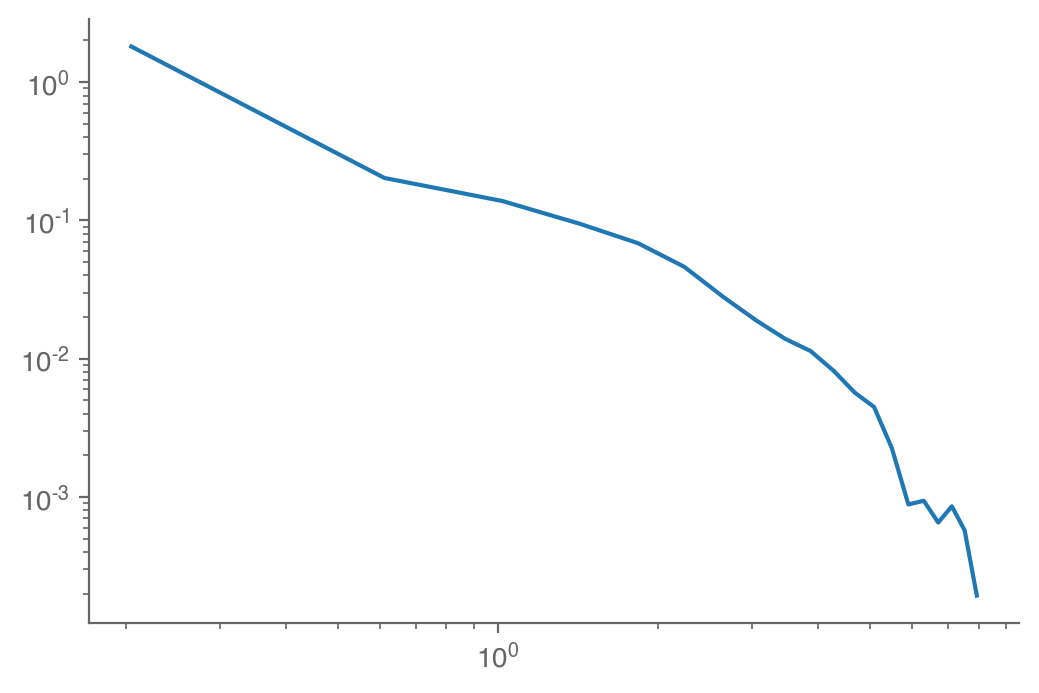

In [9]:
pdf, bin_edges = np.histogram(sr_ctrl.q, 20, density=True)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
plt.loglog(bin_centers, pdf)

In [10]:
sr_ctrl.q.max()

8.143701643410024

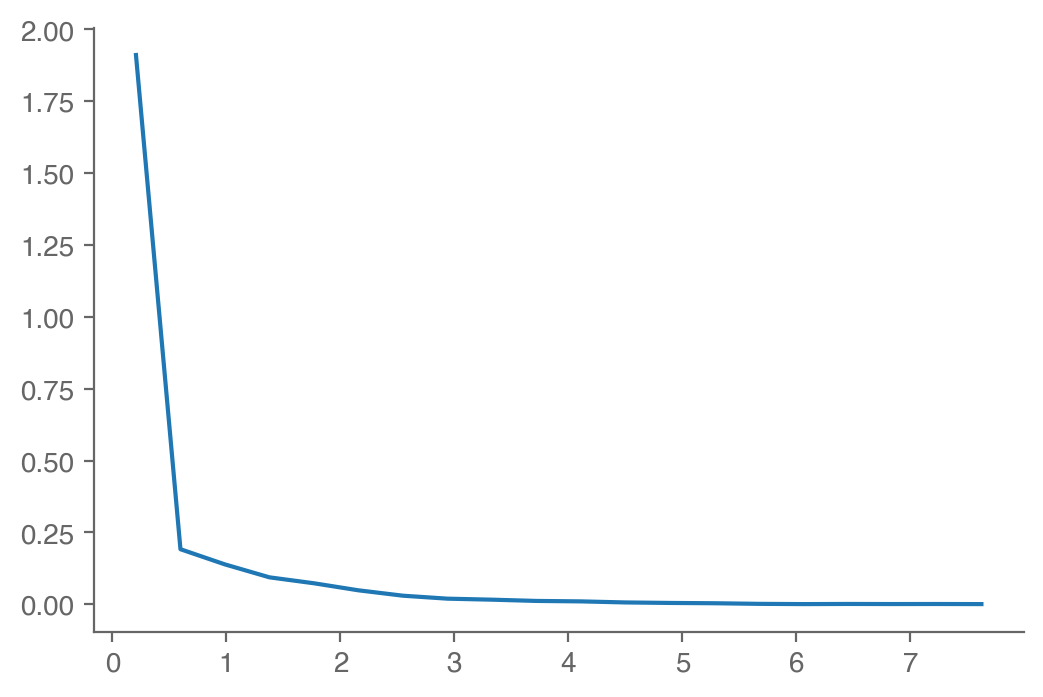

In [11]:
pdf, bin_edges = np.histogram(q_daily, 20, density=True)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
plt.plot(bin_centers, pdf)

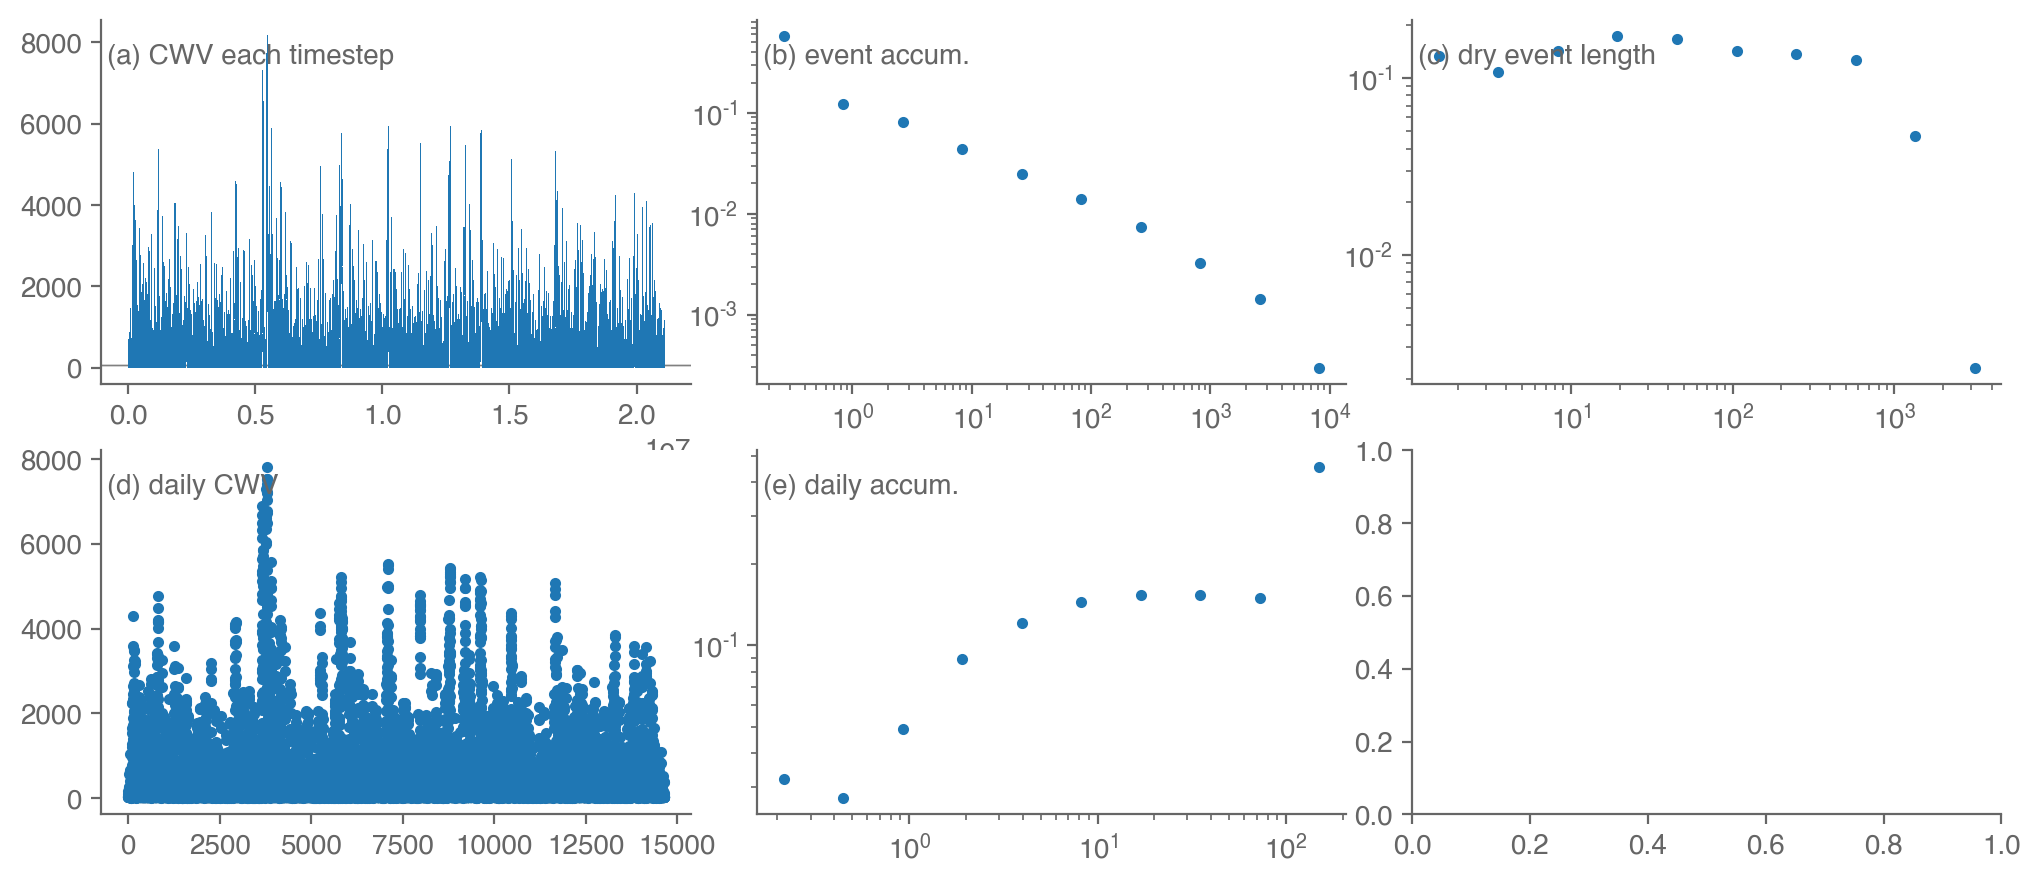

In [12]:
fig, axarr = pplt.faceted(2, 3, width=10, sharex=False, sharey=False)

n = 0
ax = axarr[n]
pplt.mark_y0(ax=ax, y0=1e3 * sr_ctrl.q_thresh_start)
pplt.mark_y0(ax=ax, y0=1e3 * sr_ctrl.q_thresh_end)
ax.plot(1e3 * sr_ctrl.q, marker=",", linestyle="none")
pplt.panel_label(n, ax=ax, extra_text="CWV each timestep")

n = 1
ax = axarr[n]
dens_accum, log_bin_edges_accum = np.histogram(np.log(sr_ctrl.rain_event_accums), density=True)
log_bin_centers_accum = 0.5 * (log_bin_edges_accum[1:] + log_bin_edges_accum[:-1])
bin_centers_accum = np.exp(log_bin_centers_accum)
ax.loglog(1e3 * bin_centers_accum, dens_accum, linestyle="none", marker=".")
pplt.panel_label(n, ax=ax, extra_text="event accum.")

n = 2
ax = axarr[n]
dens_dry_len, log_bin_edges_dry_len = np.histogram(np.log(sr_ctrl.dry_event_lengths), density=True)
log_bin_centers_dry_len = 0.5 * (log_bin_edges_dry_len[1:] + log_bin_edges_dry_len[:-1])
bin_centers_dry_len = np.exp(log_bin_centers_dry_len)
ax.loglog(bin_centers_dry_len, dens_dry_len, linestyle="none", marker=".")
pplt.panel_label(n, ax=ax, extra_text="dry event length")

n = 3
ax = axarr[n]
ax.plot(1e3 * q_daily, marker=".", linestyle="none")
pplt.panel_label(n, ax=ax, extra_text="daily CWV")

n = 4
ax = axarr[n]
dens_accum_daily, log_bin_edges_accum_daily = np.histogram(np.log(accums_daily[np.where(accums_daily > 0)]), density=True)
log_bin_centers_accum_daily = 0.5 * (log_bin_edges_accum_daily[1:] + log_bin_edges_accum_daily[:-1])
bin_centers_accum_daily = np.exp(log_bin_centers_accum_daily)
ax.loglog(1e3 * bin_centers_accum_daily, dens_accum_daily, linestyle="none", marker=".")
pplt.panel_label(n, ax=ax, extra_text="daily accum.")

## "El Nino"

In [13]:
elnino_wet_factor = 1.5
elnino_dry_factor = 1.

sr_elnino = StochRain(
    q_thresh_start=65.0, 
    q_thresh_end=64.8, 
    q_init=64.9, 
    q_min=1., 
    noise_amp_wet=17.0 * scaling_factor_wet * elnino_wet_factor, 
    noise_amp_dry=3.0 * scaling_factor_dry * elnino_dry_factor, 
    dt=dt,
    evap_clim=0.1,
    moist_flux_conv_clim=0.2,
    rain_rate=9.,
)
sr_elnino.run(num_hours / dt)
q_daily_en, accums_daily_en, num_dry_days_en = sr_elnino.daily_avg()

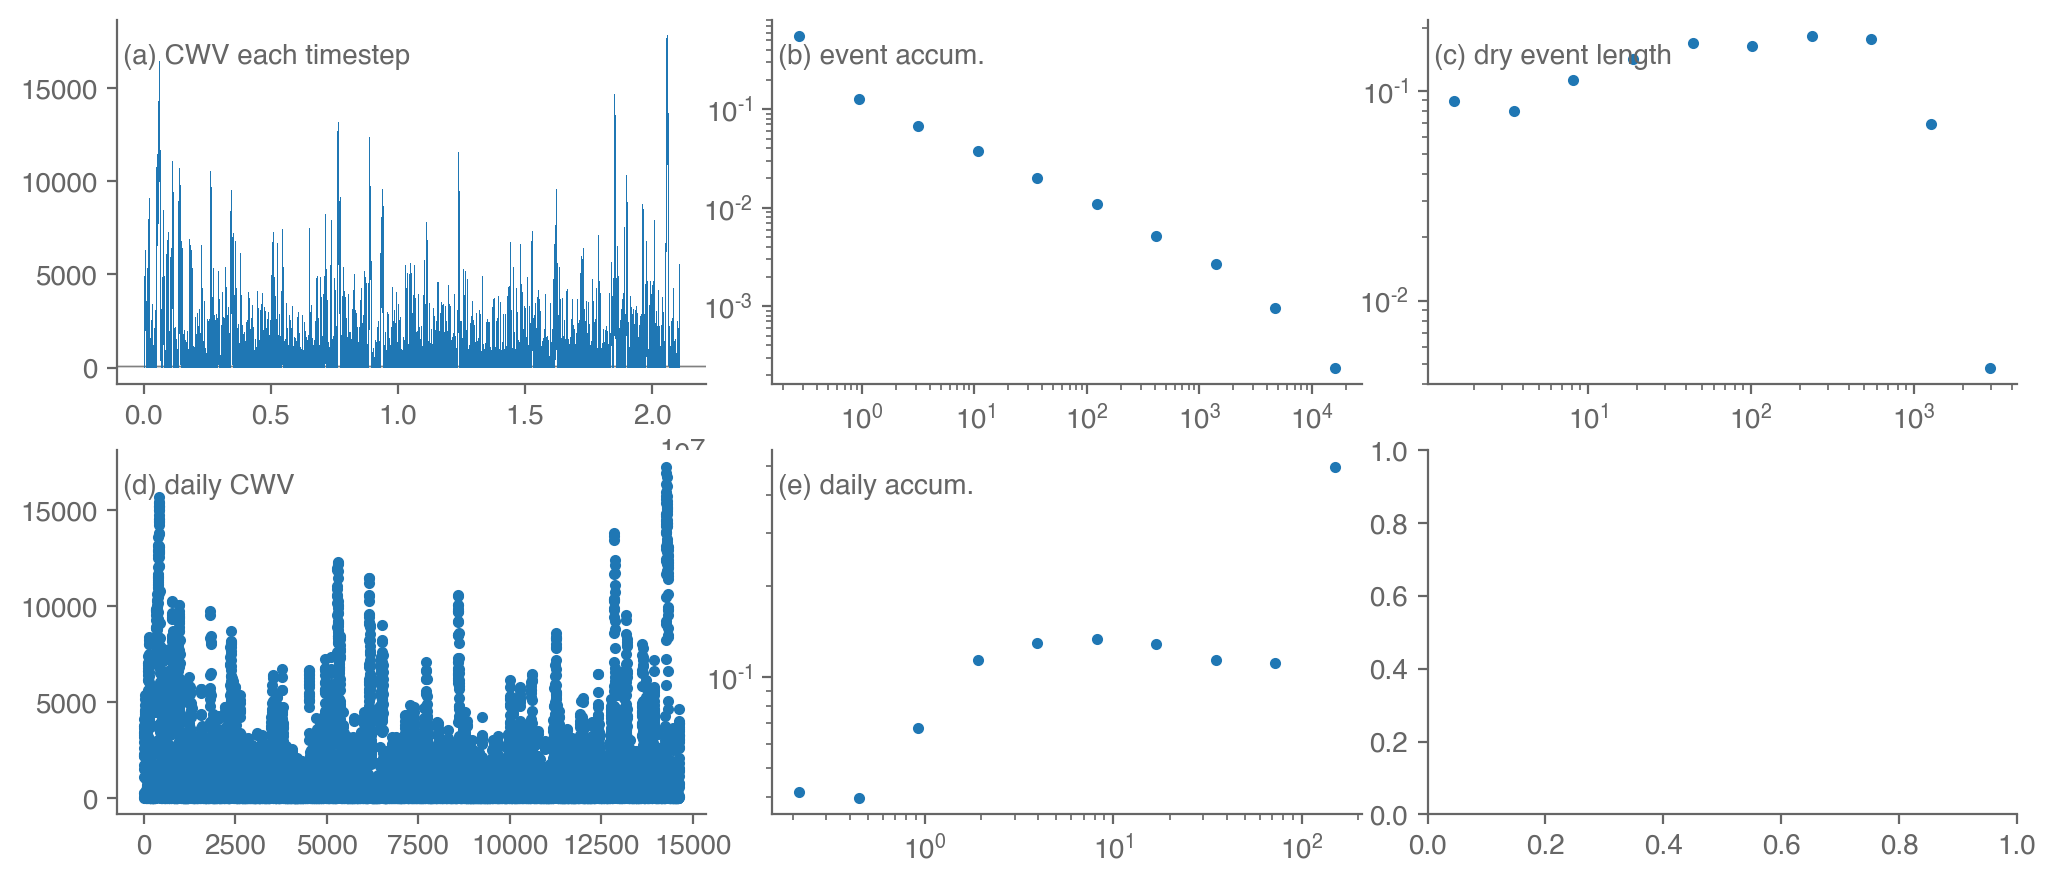

In [14]:
fig, axarr = pplt.faceted(2, 3, width=10, sharex=False, sharey=False)

sr = sr_elnino
qd = q_daily_en
accd = accums_daily_en
ndd = num_dry_days_en

n = 0
ax = axarr[n]
pplt.mark_y0(ax=ax, y0=1e3 * sr.q_thresh_start)
pplt.mark_y0(ax=ax, y0=1e3 * sr.q_thresh_end)
ax.plot(1e3 * sr.q, marker=",", linestyle="none")
pplt.panel_label(n, ax=ax, extra_text="CWV each timestep")

n = 1
ax = axarr[n]
dens_accum_en, log_bin_edges_accum_en = np.histogram(np.log(sr.rain_event_accums), density=True)
log_bin_centers_accum_en = 0.5 * (log_bin_edges_accum_en[1:] + log_bin_edges_accum_en[:-1])
bin_centers_accum_en = np.exp(log_bin_centers_accum_en)
ax.loglog(1e3 * bin_centers_accum_en, dens_accum_en, linestyle="none", marker=".")
pplt.panel_label(n, ax=ax, extra_text="event accum.")

n = 2
ax = axarr[n]
dens_dry_len_en, log_bin_edges_dry_len_en = np.histogram(np.log(sr.dry_event_lengths), density=True)
log_bin_centers_dry_len_en = 0.5 * (log_bin_edges_dry_len_en[1:] + log_bin_edges_dry_len_en[:-1])
bin_centers_dry_len_en = np.exp(log_bin_centers_dry_len_en)
ax.loglog(bin_centers_dry_len_en, dens_dry_len_en, linestyle="none", marker=".")
pplt.panel_label(n, ax=ax, extra_text="dry event length")

n = 3
ax = axarr[n]
ax.plot(1e3 * qd, marker=".", linestyle="none")
pplt.panel_label(n, ax=ax, extra_text="daily CWV")

n = 4
ax = axarr[n]
dens_accum_en_daily, log_bin_edges_accum_en_daily = np.histogram(np.log(accd[np.where(accd > 0)]), density=True)
log_bin_centers_accum_en_daily = 0.5 * (log_bin_edges_accum_en_daily[1:] + log_bin_edges_accum_en_daily[:-1])
bin_centers_accum_en_daily = np.exp(log_bin_centers_accum_en_daily)
ax.loglog(1e3 * bin_centers_accum_en_daily, dens_accum_en_daily, linestyle="none", marker=".")
pplt.panel_label(n, ax=ax, extra_text="daily accum.")

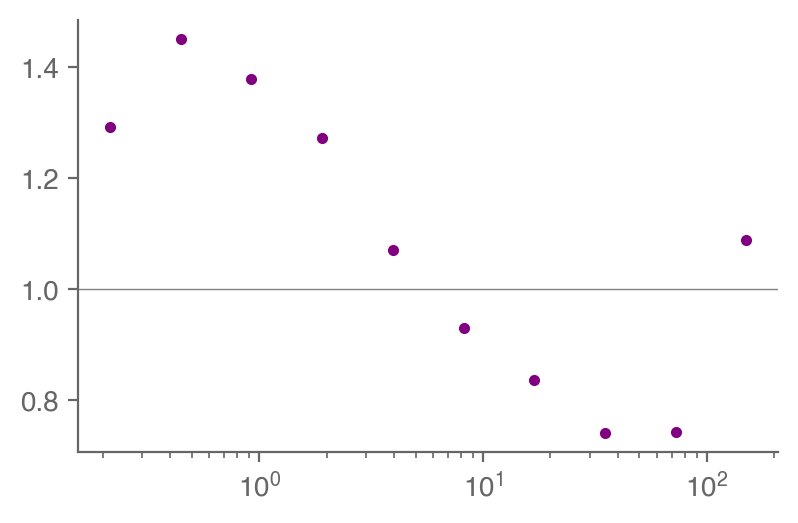

In [15]:
fig, ax = pplt.faceted_ax()
pplt.mark_y0(ax=ax, y0=1)
ax.semilogx(1e3 * bin_centers_accum_daily, dens_accum_en_daily / dens_accum_daily, linestyle="none", marker=".", color="purple")

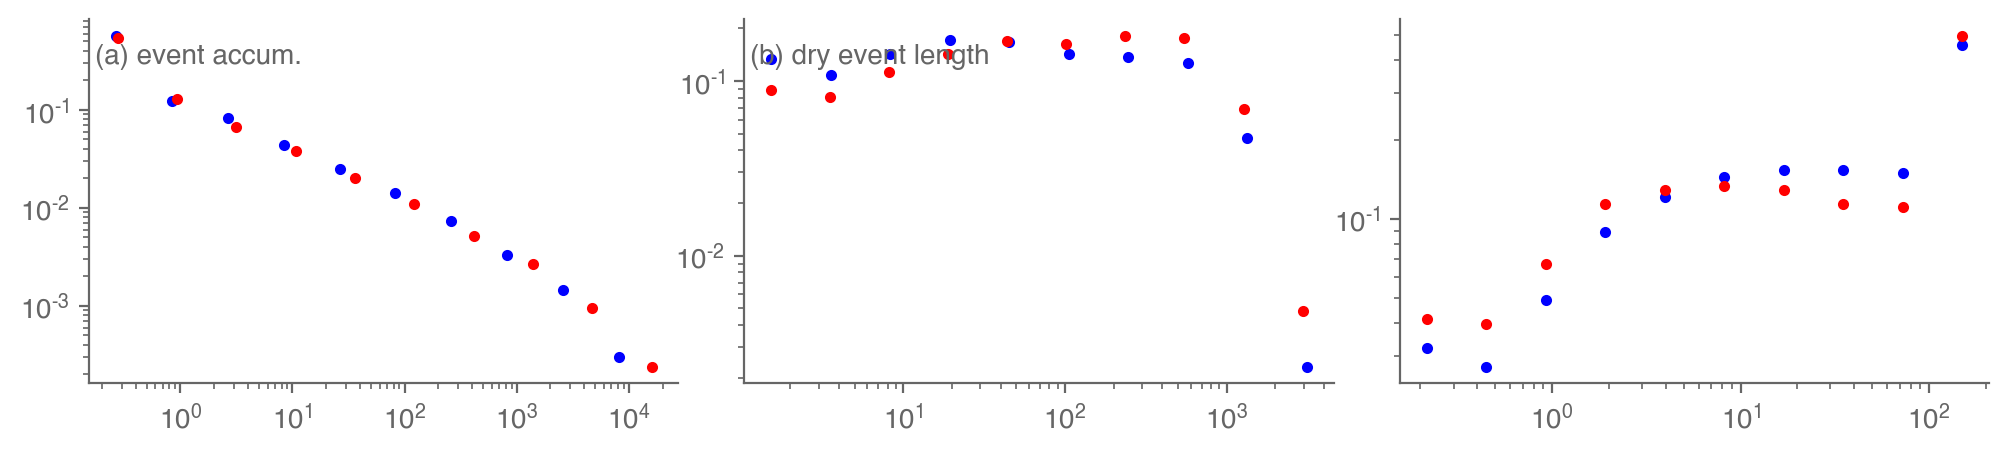

In [16]:
fig, axarr = pplt.faceted(1, 3, width=10, sharex=False, sharey=False)

n = 0
ax = axarr[n]
ax.loglog(1e3 * bin_centers_accum, dens_accum, linestyle="none", marker=".", color="blue")
ax.loglog(1e3 * bin_centers_accum_en, dens_accum_en, linestyle="none", marker=".", color="red")
pplt.panel_label(n, ax=ax, extra_text="event accum.")

n = 1
ax = axarr[n]
ax.loglog(bin_centers_dry_len, dens_dry_len, linestyle="none", marker=".", color="blue")
ax.loglog(bin_centers_dry_len_en, dens_dry_len_en, linestyle="none", marker=".", color="red")
pplt.panel_label(n, ax=ax, extra_text="dry event length")

n = 2
ax = axarr[n]
ax.loglog(1e3 * bin_centers_accum_daily, dens_accum_daily, linestyle="none", marker=".", color="blue")
ax.loglog(1e3 * bin_centers_accum_en_daily, dens_accum_en_daily, linestyle="none", marker=".", color="red")
# pplt.panel_label(n, ax=ax, extra_text="daily accum.")